In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report
from sklearn import metrics
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import os


In [105]:
col_names = ["Age","Sex","BP","Cholesterol","Na_to_K","Drug"]
pima = pd.read_csv("drugs.csv", header=0, names=col_names)
df = pima

In [106]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["Sex"] = le.fit_transform(df["Sex"])
df["BP"] = le.fit_transform(df["BP"])
df["Cholesterol"] = le.fit_transform(df["Cholesterol"])

df["Drug"] = df["Drug"].map({"drugA": 0, "drugB": 0,"drugC": 0,"drugX": 1,"drugY": 1})

In [107]:
#Selección de las características
feature_cols =["Age","Sex","BP","Cholesterol","Na_to_K"]
X = df[feature_cols]
y = df.Drug


In [108]:
#sag: Stochastic Average Gradient
#newton-cg: Library for large linear classification (Algoritmo Coordinante Descent)
#saga: Variante del método sag
#lbfgs: Limited-memory Broyned_Fletcher_Goldfarb_Shanno Algoritm


# Regresión logística con Solucionador (Solver): sag

In [109]:
model= LogisticRegression(solver ="sag")
clf = model.fit(X_train, y_train)

In [110]:
#Predicción de etiquetas de clase sobre datos de prueba
y_pred = model.predict (X_test)

#Impresión de coeficientes de la regresión de puntajes
print ("Intercepto (Beta 0)", clf.intercept_)
print("Pesos de cada variable /Beta1,Beta2,...,Beta5)", clf.coef_)

Intercepto (Beta 0) [-0.3423]
Pesos de cada variable /Beta1,Beta2,...,Beta5) [[-0.0382 -0.1361  0.9917  0.2324  0.1653]]


In [111]:
#Evaluación de la presición del modelo
score = model.score(X_test,y_test)
print("Score de precisión:",score)

Score de precisión: 0.825


In [112]:
#Reporte de clasificación
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.75      0.33      0.46         9
           1       0.83      0.97      0.90        31

    accuracy                           0.82        40
   macro avg       0.79      0.65      0.68        40
weighted avg       0.81      0.82      0.80        40



# Regresión logística con Solucionador (Solver): newton-cg

In [113]:
import numpy as np
np.set_printoptions(precision=4, suppress=True)

In [114]:
model = LogisticRegression(solver="newton-cg")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0):",clf.intercept_)
print("Pesos (Betas):",clf.coef_)
print("-----------------------------------------------------------")
score=model.score(X_test, y_test)
print("Precición global:", score)
print("-----------------------------------------------------------")
print(classification_report(y_test,y_pred))

Intercepto (Beta0): [-11.9093]
Pesos (Betas): [[0.0115 0.2503 3.2437 2.0861 0.6666]]
-----------------------------------------------------------
Precición global: 0.95
-----------------------------------------------------------
              precision    recall  f1-score   support

           0       0.89      0.89      0.89         9
           1       0.97      0.97      0.97        31

    accuracy                           0.95        40
   macro avg       0.93      0.93      0.93        40
weighted avg       0.95      0.95      0.95        40



# Regresión logística con Solucionador (Solver): liblinear

In [115]:
model = LogisticRegression(solver="liblinear")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0):",clf.intercept_)
print("Pesos (Betas):",clf.coef_)
print("-----------------------------------------------------------")
score=model.score(X_test, y_test)
print("Precición global:", score)
print("-----------------------------------------------------------")
print(classification_report(y_test,y_pred))

Intercepto (Beta0): [-3.4745]
Pesos (Betas): [[-0.0261 -0.2196  1.961   1.1363  0.2752]]
-----------------------------------------------------------
Precición global: 0.975
-----------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      0.89      0.94         9
           1       0.97      1.00      0.98        31

    accuracy                           0.97        40
   macro avg       0.98      0.94      0.96        40
weighted avg       0.98      0.97      0.97        40



# Regresión logística con Solucionador (Solver): saga

In [116]:
model = LogisticRegression(solver="saga")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0):",clf.intercept_)
print("Pesos (Betas):",clf.coef_)
print("-----------------------------------------------------------")
score=model.score(X_test, y_test)
print("Precición global:", score)
print("-----------------------------------------------------------")
print(classification_report(y_test,y_pred))

Intercepto (Beta0): [-0.1597]
Pesos (Betas): [[-0.0349 -0.0731  0.6379  0.1299  0.161 ]]
-----------------------------------------------------------
Precición global: 0.825
-----------------------------------------------------------
              precision    recall  f1-score   support

           0       0.75      0.33      0.46         9
           1       0.83      0.97      0.90        31

    accuracy                           0.82        40
   macro avg       0.79      0.65      0.68        40
weighted avg       0.81      0.82      0.80        40



# Regresión logística con Solucionador (Solver): lbfgs

In [117]:
model = LogisticRegression(solver="lbfgs")
clf = model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Intercepto (Beta0):",clf.intercept_)
print("Pesos (Betas):",clf.coef_)
print("-----------------------------------------------------------")
score=model.score(X_test, y_test)
print("Precición global:", score)
print("-----------------------------------------------------------")
print(classification_report(y_test,y_pred))

Intercepto (Beta0): [-11.9532]
Pesos (Betas): [[0.0116 0.2539 3.2506 2.0924 0.6687]]
-----------------------------------------------------------
Precición global: 0.95
-----------------------------------------------------------
              precision    recall  f1-score   support

           0       0.89      0.89      0.89         9
           1       0.97      0.97      0.97        31

    accuracy                           0.95        40
   macro avg       0.93      0.93      0.93        40
weighted avg       0.95      0.95      0.95        40



In [118]:
# Predicción de probabilidades para casos particuleres
y_pred_probs = clf.predict_proba(X_test)[:,1]
y_pred_probs[0:5]

array([0.1127, 0.583 , 0.9089, 0.732 , 0.8639])

In [119]:
y_test[0:5]

array([0, 0, 1, 1, 1])

In [120]:
import numpy as np
y_pred_probs = np.round(y_pred_probs,0)
y_pred_probs[0:5]


array([0., 1., 1., 1., 1.])

In [121]:
#Graficación de la curva ROC y cálculo del área bajo ella
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score

#fpr =false positive rate
#tpr = true positive rate
#threshols = limites para valores de p

fpr,tpr, thresholds = roc_curve(y_test,y_pred_probs)
auc = roc_auc_score(y_test, y_pred_probs)

Text(0.5, 1.0, 'Curva ROC para Regresión Logística')

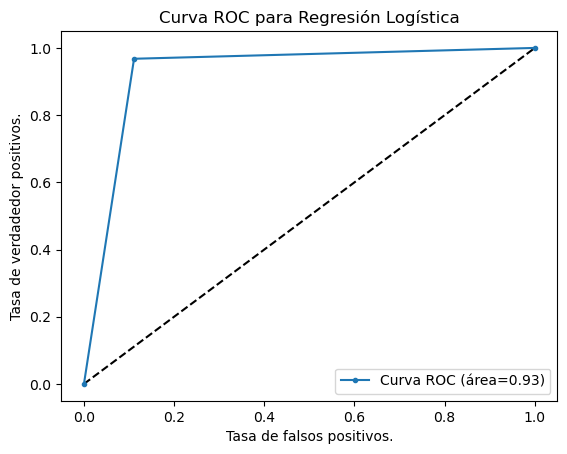

In [122]:
plt.plot([0,1],[0,1], 'k--')
plt.plot (fpr,tpr,marker=".",label = "Curva ROC (área=%0.2f)" % auc)
plt.xlabel("Tasa de falsos positivos.")
plt.ylabel("Tasa de verdadedor positivos.")
plt.legend(loc= "lower right")
plt.title("Curva ROC para Regresión Logística")